# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data. 

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Kaitlin Luu, Natalie Schweickert, James Torgerson"

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.


In [1]:
import pandas as pd

train = pd.read_csv('data/iot_devices_train.csv')
report = pd.read_csv('data/iot_devices_reporting.csv')

In [2]:
train.head()

,ack,ack_A,ack_B,bytes,bytes_A,bytes_A_B_ratio,bytes_B,ds_field_A,ds_field_B,duration,...,suffix_is_co.il,suffix_is_com,suffix_is_com.sg,suffix_is_else,suffix_is_empty_char_value,suffix_is_googleapis.com,suffix_is_net,suffix_is_org,suffix_is_unresolved,device_category
0,9,5,5,1213,743,0.713924,668,0,0,1.5756,...,0,0,0,1,0,0,0,0,0,security_camera
1,9,5,5,1213,743,1.806874,668,0,0,0.6890,...,0,0,0,1,0,0,0,0,0,security_camera
2,9,5,5,1213,743,0.103124,668,0,0,0.9852,...,0,0,0,1,0,0,0,0,0,security_camera
3,9,5,5,1213,743,1.806874,668,0,0,1.5756,...,0,0,0,1,0,0,0,0,0,security_camera
4,9,5,5,1213,743,1.806874,668,0,0,1.5756,...,0,0,0,1,0,0,0,0,0,security_camera


In [3]:
report.head()

,ack,ack_A,ack_B,bytes,bytes_A,bytes_A_B_ratio,bytes_B,ds_field_A,ds_field_B,duration,...,suffix_is_co.il,suffix_is_com,suffix_is_com.sg,suffix_is_else,suffix_is_empty_char_value,suffix_is_googleapis.com,suffix_is_net,suffix_is_org,suffix_is_unresolved,device_category
0,38,20,18,14698,7814,1.135096,6884,0,0,1.9156,...,0,0,0,1,0,0,0,0,0,baby_monitor
1,38,20,18,14698,7814,1.135096,6884,0,0,2.0020,...,0,0,0,1,0,0,0,0,0,baby_monitor
2,38,20,18,14762,7814,1.124640,6948,0,0,2.1833,...,0,0,0,1,0,0,0,0,0,baby_monitor
3,38,20,18,14762,7814,1.124640,6948,0,0,2.1521,...,0,0,0,1,0,0,0,0,0,baby_monitor
4,41,20,21,14862,7994,1.163949,6868,0,0,2.2422,...,0,0,0,1,0,0,0,0,0,baby_monitor


2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

In [4]:
y_train = train['device_category']
X_train = train.drop(columns='device_category')

y_report = report['device_category']
X_report = report.drop(columns='device_category')

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.


In [5]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y_train_enc = encoder.fit_transform(y_train)
y_report_enc = encoder.transform(y_report)

print(y_train_enc)
print(y_report_enc)

[4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 5 5 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7
 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7
 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 7 8 8 8 8 8 8 8
 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8
 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8
 8 8 8 8 8 8 8 8 8 8 8 8 

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

In [6]:
import umap
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# pipeline with standardize and 2 components 
pca_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2)),
])
umap_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('umap', umap.UMAP(n_components=2, random_state=42)),
])

projections = {
    'PCA': pca_pipe.fit_transform(X_train),
    'UMAP': umap_pipe.fit_transform(X_train),
}

C:\Users\kaitl\AppData\Roaming\Python\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

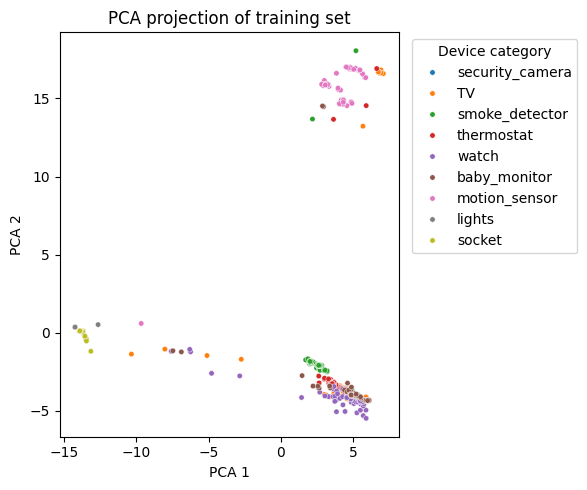

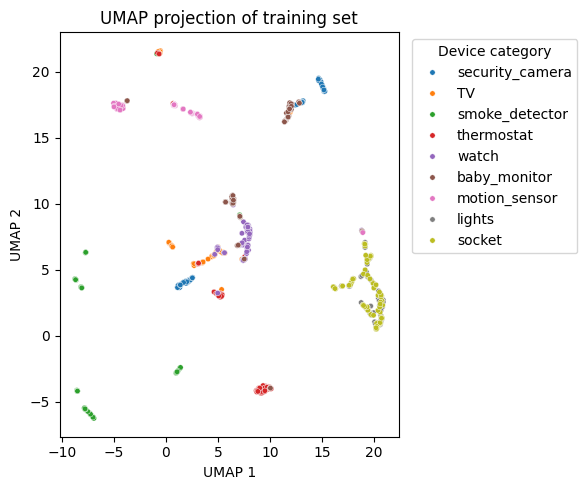

In [7]:
for name, coords in projections.items():
    plt.figure(figsize=(6, 5))
    sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=y_train, s=15)
    plt.title(f'{name} projection of training set')
    plt.xlabel(f'{name} 1')
    plt.ylabel(f'{name} 2')
    plt.legend(title='Device category', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?

The PCA visualization groups the points into 2 groups, the top right and the bottom row. The UMAP visualization groups points throughout the grid. UMAP appears to group the points by device category while there is more overlap in PCA. UMAP seems to give better information about the structure in the data because device categories are shows more easily.

## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.


Scaling and normalizations aren't needed for tree-based models. A tree splits each feature at a threshold, and scaling is a monotonic transformation, so it keeps the order of the values and produces the same splits and predictions. Because the splits depend only on order and not magnitude, standardizing the features would change nothing about the model’s decisions. Encoding is still required for text columns, since scikit-learn’s trees need numeric input.

2. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

In [11]:
import numpy as np
from time import time
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier

# use the same 5-fold stratified cross-validation for both models
# shuffling distributes observations across folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# test the same candidate values for max_depth in both models
depth_values = [3, 5, 10]

# Gradient Boosting
gb_param_grid = {
    'max_depth': depth_values,
    'learning_rate': [0.01, 0.1, 0.5],
}
gb_search = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid=gb_param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
)

# track how long the hyperparameter search takes
start = time()
gb_search.fit(X_train, y_train_enc)
gb_time = (time() - start) / 60

print('Gradient Boosting')
print('Best params:', gb_search.best_params_)
print(f'Best CV accuracy: {gb_search.best_score_:.4f}')
print(f'Search time: {gb_time:.4f} minutes')


# Random Forest
rf_param_grid = {
    'max_depth': depth_values,
    'max_features': ['sqrt', 'log2', 0.3],
}
rf_search = GridSearchCV(
    RandomForestClassifier(n_estimators=200, random_state=42),
    param_grid=rf_param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
)

# track how long it takes to find the best hyperparameter combo
start = time()
rf_search.fit(X_train, y_train_enc)
rf_time = (time() - start) / 60

print('\nRandom Forest')
print('Best params:', rf_search.best_params_)
print(f'Best CV accuracy: {rf_search.best_score_:.4f}')
print(f'Search time: {rf_time:.4f} minutes')

Gradient Boosting
Best params: {'learning_rate': 0.1, 'max_depth': 3}
Best CV accuracy: 0.8900
Search time: 2.1256 minutes

Random Forest
Best params: {'max_depth': 10, 'max_features': 'log2'}
Best CV accuracy: 0.8900
Search time: 0.1061 minutes


3. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

Gradient Boosting: reporting accuracy = 0.6811 | search time = 2.1256 min
                 precision    recall  f1-score   support

             TV       0.49      0.78      0.60       100
   baby_monitor       0.96      0.74      0.84       100
         lights       0.69      0.49      0.57       100
  motion_sensor       0.93      0.56      0.70       100
security_camera       0.92      0.34      0.50       100
 smoke_detector       1.00      1.00      1.00       100
         socket       0.59      0.77      0.67       100
     thermostat       0.63      0.92      0.75       100
          watch       0.43      0.53      0.48       100

       accuracy                           0.68       900
      macro avg       0.74      0.68      0.68       900
   weighted avg       0.74      0.68      0.68       900

Random Forest: reporting accuracy = 0.6756 | search time = 0.1061 min
                 precision    recall  f1-score   support

             TV       0.36      0.41      0.38       1

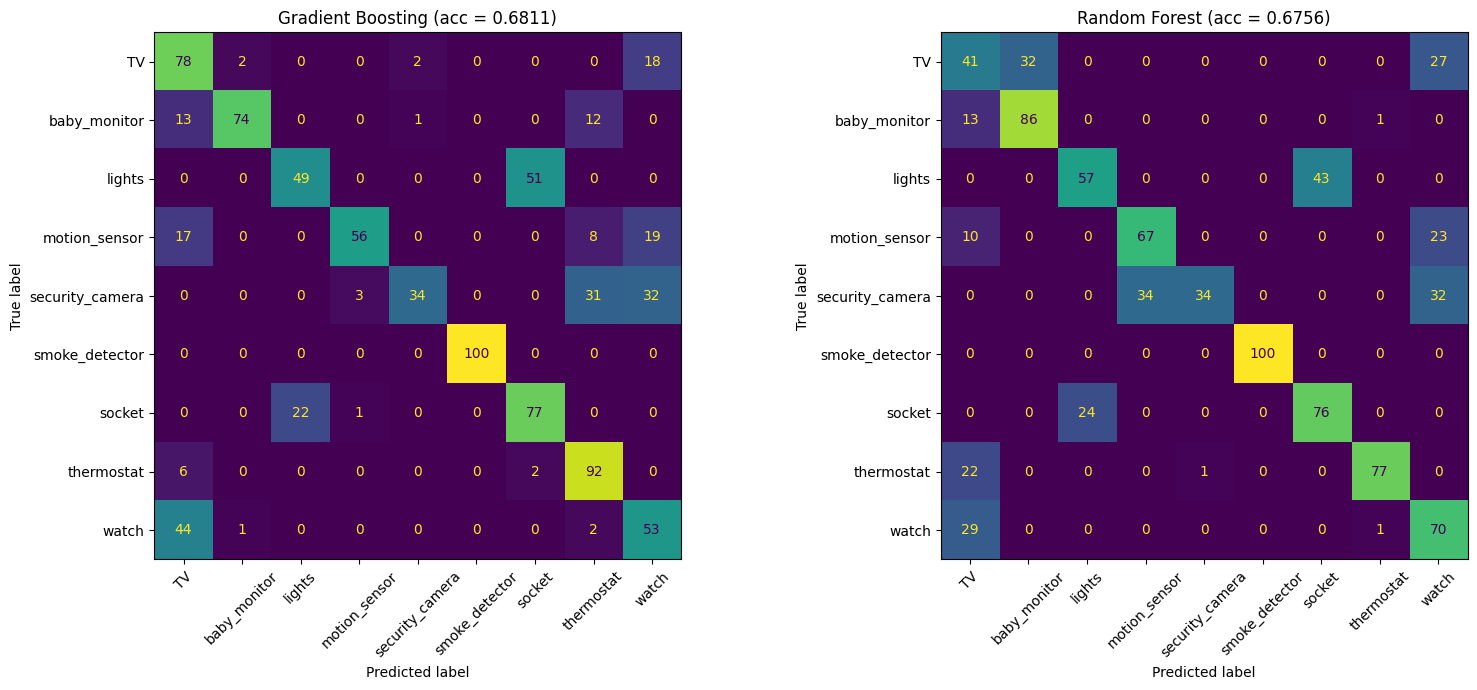

In [16]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# get class labels from fitted label encoder
class_names = encoder.classes_
# store both models for comparison
models = {
    'Gradient Boosting': (gb_search, gb_time),
    'Random Forest': (rf_search, rf_time),
}

# make confusion matrices to compare model predictions
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, (search, t)) in zip(axes, models.items()):
    y_pred = search.best_estimator_.predict(X_report)
    acc = accuracy_score(y_report_enc, y_pred)
    print(f'{name}: reporting accuracy = {acc:.4f} | search time = {t:.4f} min')
    print(classification_report(y_report_enc, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_report_enc, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(f'{name} (acc = {acc:.4f})')
plt.tight_layout()
plt.show()

In [17]:
# calculate per-class accuracy (recall) to see which devices are easiest/hardest to predict
per_class = pd.DataFrame({
    name: confusion_matrix(y_report_enc, s.best_estimator_.predict(X_report)).diagonal()
          / confusion_matrix(y_report_enc, s.best_estimator_.predict(X_report)).sum(axis=1)
    for name, (s, _) in models.items()
}, index=class_names)
print(per_class.sort_values('Random Forest', ascending=False).round(3))

                 Gradient Boosting  Random Forest
smoke_detector                1.00           1.00
baby_monitor                  0.74           0.86
thermostat                    0.92           0.77
socket                        0.77           0.76
watch                         0.53           0.70
motion_sensor                 0.56           0.67
lights                        0.49           0.57
TV                            0.78           0.41
security_camera               0.34           0.34


4. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.

In [ ]:
from scipy.stats import spearmanr

gb_imp = pd.Series(gb_search.best_estimator_.feature_importances_, index=X_train.columns)
rf_imp = pd.Series(rf_search.best_estimator_.feature_importances_, index=X_train.columns)

# quantitative comparison: how similarly the two models rank and assign importance to features
cos = np.dot(gb_imp, rf_imp) / (np.linalg.norm(gb_imp) * np.linalg.norm(rf_imp))
pearson = np.corrcoef(gb_imp, rf_imp)[0, 1]
spearman = spearmanr(gb_imp, rf_imp).correlation
k = 20
top_gb, top_rf = set(gb_imp.nlargest(k).index), set(rf_imp.nlargest(k).index)

# print similarity measurements and number of shared top features
print(f'Cosine similarity: {cos:.3f}')
print(f'Pearson correlation: {pearson:.3f}')
print(f'Spearman rank correlation: {spearman:.3f}')
print(f'Overlap in top-{k} features: {len(top_gb & top_rf)}/{k}')
print('Shared top features:', sorted(top_gb & top_rf))

Cosine similarity: 0.665
Pearson correlation: 0.630
Spearman rank correlation: 0.891
Overlap in top-20 features: 10/20
Shared top features: ['packet_inter_arrivel_A_min', 'packet_inter_arrivel_A_sum', 'packet_inter_arrivel_firstQ', 'packet_inter_arrivel_min', 'packet_inter_arrivel_sum', 'ttl_B_max', 'ttl_B_min', 'ttl_avg', 'ttl_max', 'ttl_min']


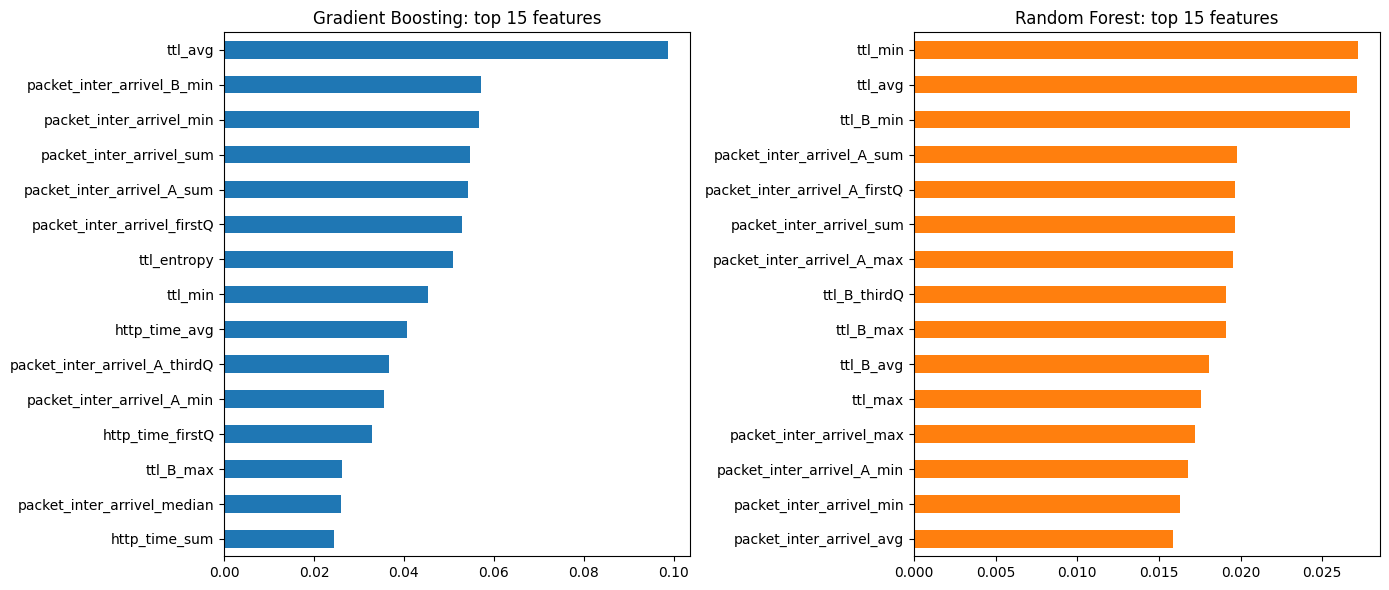

In [ ]:
# qualitative comparison: visualize the top 15 most important features from each model
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
gb_imp.nlargest(15).sort_values().plot.barh(ax=axes[0], color='tab:blue', title='Gradient Boosting: top 15 features')
rf_imp.nlargest(15).sort_values().plot.barh(ax=axes[1], color='tab:orange', title='Random Forest: top 15 features')
plt.tight_layout()
plt.show()

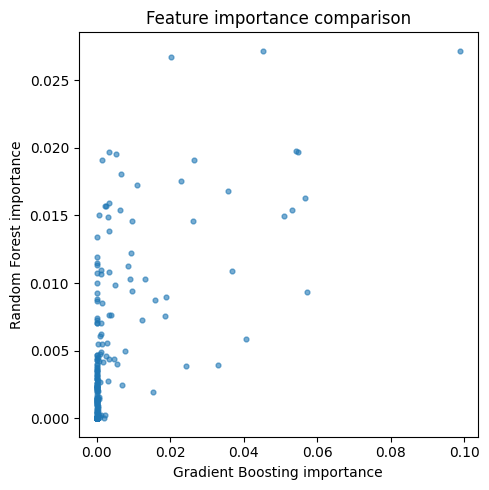

In [ ]:
# scatterplot to compare individual feature importance scores across both models
plt.figure(figsize=(5, 5))
plt.scatter(gb_imp, rf_imp, s=12, alpha=0.6)
plt.xlabel('Gradient Boosting importance')
plt.ylabel('Random Forest importance')
plt.title('Feature importance comparison')
plt.tight_layout()
plt.show()

5. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

With 9 device categories, random guessing would produce an accuracy of around 1/9 or 11.1%, which is far below the baseline of 50%. Since the reporting set has 100 samples per class, each class is equally represented, so both models performed much better than chance. Gradient Boosting achieved an accuracy of 68.11% and Random Forest achieved 67.56%. These are both much higher than random guessing. This indicates that both models learned patterns in the data that helped distinguish between device categories. Even the class that was hardest to predict, security_camera, had 34% recall, while smoke_detector was classified perfectly. Overall both of the models performed significantly better than random guessing. 

## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

The main differences between HistGradientBoostingClassifier and GradientBoostingClassifier are that HistGradientBoostingClassifier is much faster for larger datasets (tens of thousands of samples or more) and has built-in support for missing values and categorical features, which reduces the need for preprocessing. GradientBoostingClassifier may be preferred for smaller datasets because histogram binning can make the split points less precise.


The histogram binning makes training faster because it groups feature values into a limited number of bins (typically 256), which reduces the number of possible splitting points the algorithm needs to consider. It does not require repeatedly sorting the feature values and instead uses a data structure called a histogram, where the samples are implicitly ordered. It is also faster because it uses second-order information about the loss, i.e. the Hessian. This is called Newton boosting and avoids the line-search step of ordinary gradient boosting.

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.

In [ ]:
# USE AS MANY CELLS AS NEEDED

4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

Scaling is necessary for a neural network. MLPClassifier computes weighted sums of its inputs and learns through gradient descent, so features with large ranges dominate those sums and slow convergence. Standardizing the features puts them on comparable scales. Any text columns must be encoded first, since the network needs numeric input.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

In [ ]:
# USE AS MANY CELLS AS NEEDED

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE